In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

In [2]:
from artistic_pattern_gen import create_triangle, create_circle, create_rectangle, goal_generation, generate_points, euclidean_dist

## 1. Generate random Robots

In [3]:
# number of robots
n = 10

# create arena rectangle
rectangle_lower_left = (-3, -3)
rectangle_upper_right = (3, 3)
arena_rectangle = create_rectangle(rectangle_lower_left, rectangle_upper_right)

# create random robots
robots = generate_points(n, arena_rectangle)
robots = np.array([[robot.x, robot.y] for robot in robots])

## 2. generate goal positions

In [4]:
# Create a triangle
triangle_vertices = [(-1, -1), (1, -1), (0, 1)]
polygon = create_triangle(triangle_vertices)
goal_positions = goal_generation(polygon, n)

## 3. Create distance matrix

The nxn distance matrix has been created. The first dimension is the robots, the second dimension is the goal positions

In [5]:
distances = np.zeros((n, n))

for i, robot in enumerate(robots):
    for j, goal_position in enumerate(goal_positions):
        dist = np.sqrt( (robot[0] - goal_position[0])**2 + (robot[1] - goal_position[1])**2 )

        distances[i][j] = dist**2

## 4. Apply hungarian algorithm
For the hungarian algorithm I use the scipy linear_sum_assignment function

In [6]:
assigned_positions = linear_sum_assignment(distances, maximize=False)

In [7]:
assigned_positions

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([0, 2, 8, 5, 9, 4, 1, 7, 6, 3]))

## 5. Plot results

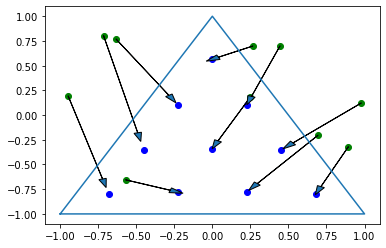

In [8]:
plt.figure()
plt.plot(*polygon.exterior.xy)

for robot in robots:
    plt.scatter(robot[0], robot[1], color='green')

for goal_pos in goal_positions:
    plt.scatter(goal_pos[0], goal_pos[1], color='blue')

for robot_idx, goal_idx in zip(assigned_positions[0], assigned_positions[1]):
    robot = robots[robot_idx]
    goal_pos = goal_positions[goal_idx]
    plt.arrow(
        robot[0],
        robot[1], 
        0.85 * (goal_pos[0] - robot[0]), 
        0.85 * (goal_pos[1] - robot[1]),
        head_width=0.05,
        head_length=0.09
    )

## 5. Preferred velocity

In [10]:
def preferred_velocity(robot_pos, goal_pos, max_speed, Ka):
    Vp = 0.9 * max_speed
    a = np.min(1, (euclidean_dist(robot_pos, goal_pos) / Ka))

    return Vp * a

In [11]:
# TODO: implement preferred velocityu with ROS callback (current position)